# Projekt: Salary Prediction
**Gruppe 1: Adam, Farouk El Barbari, Dardan, Thies**

**Gliederung:**
1. Analyseziel
2. Genutzte Module und ihre Funktionen
3. Datenverwaltung
    - Einlesen der Daten und Datenüberblick
    - Prüfen und die Bereinung der Daten
4. Visualisierung der Daten
5. Train-Test-Split
6. Data Preprocessing
7. Model anlegen und Validieren
    - Lineare Regression
    - KNN mit Hyperparameter K
8. Abschließende Beurteilung der Modelle

# 1. Analyseziel:

Das Ziel dieser Analyse ist es, ein Modell zu entwickeln, das in der Lage ist, das Gehalt (Salary) von Personen auf der Basis ihrer gegebenen Merkmale bzw. Daten vorherzusagen. Der Datensatz enthält verschiedene Merkmale, darunter das Alter (Age), das Geschlecht (Gender), den Bildungsgrad (Education Level), den Jobtitel (Job Title), die Berufserfahrung (Years of Experience) und das tatsächliche Gehalt(salary). Durch die Anwendung statistischer und maschineller Lernverfahren soll ein Modell trainiert werden, das in der Lage ist, den Gehaltswert für neue, unbekannte Datenpunkte vorherzusagen.

Die Aufgabe umfasst die Vorverarbeitung der Daten, die Identifikation relevanter Merkmale, das Training eines geeigneten Vorhersagemodells und die Evaluierung seiner Leistungsfähigkeit. Ein wichtiger Teil der Analyse wird sein, zu bestimmen, wie stark verschiedene Faktoren wie Berufserfahrung, Bildungsniveau und Jobtitel das Gehalt beeinflussen und welche Variablen die größte Vorhersagekraft haben.

Ziel ist es, mit den verfügbaren Merkmalen eine möglichst genaue und robuste Gehaltsprognose zu ermöglichen, die wertvolle Einblicke in die Gehaltsstruktur bietet.


# 2. Genutzte Module und ihre Funktionen

In [35]:
#Modul, um mit tabellarischen Daten zu arbeiten und sie zu analysieren (bzw. Dataframes zu bearbeiten):
import pandas as pd

#Modul/Werkzeug für schnelle und effiziente numerische Berechnungen.
import numpy as np

#Ermöglicht die schnelle und einfache Erstellung von 2D-/3D-Diagrammen und Visualisierungen.
import matplotlib.pyplot as plt

#Hilft dabei, statistische Daten zu visualisieren und informative Diagramme zu erstellen.
import seaborn as sns

# 3. Datenverwaltung:

### Einlesen der Daten und Datenüberblick

In [36]:
#Einlesen der CSV-Datei "salary.csv" bzw. unserem Datensatzes:
#Wir speichern diesen als Pandas-DataFrame "df" ein um ihn später zuverwenden:
df = pd.read_csv('/home/farouk/Uni/Data Science/Big_Project/datasets/salary.csv')

In [37]:
#Die ersten fünf Zeilen des DataFrames (df) anzeigen, um einen ersten Eindruck von den Daten zu bekommen:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [38]:
#Eine Übersicht über die Struktur bzw. alle Spalten des DataFrames:
#(Spaltennamen, Datentypen, Anzahl der Einträge pro Spalte bzw. insgesamt, Speicherverbrauch)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB


### Prüfen und die Bereinung der Daten

In [39]:
#Berechnung der Anzahl von fehlenden Werte (NaN) in jeder Spalte, um festzustellen, wo Datenbereinigung erforderlich ist:
df.isnull().sum()

Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64

In [40]:
#Anzeigen der Zeilen, die mindestens einen fehlenden Wert (NaN) enthalten:
df[df.isnull().any(axis=1)]

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
172,NaN,NaN,NaN,NaN,NaN,NaN
260,NaN,NaN,NaN,NaN,NaN,NaN


In [41]:
#Entfernung der obigen Zeilen mit den fehlenden Werten:
df = df.dropna()
#Sowie anschließende Überprüfung, ob noch fehlende Werte im DataFrame vorhanden sind:
df.isnull().sum()

Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64

In [42]:
#Überprüfung der Anzahl der doppelten Einträge (Duplikate) im Datensatz:
df.duplicated().sum()

np.int64(49)

In [43]:
#Alle doppelten Zeilen (Duplikate) aus dem DataFrame (df) entfernen:
#Grund: Daten bereinigen und sicherzustellen, dass keine redundanten Informationen die Analyse bzw. Ergebnisse stören könnten
df = df.drop_duplicates()

In [44]:
#Zusammenfassung der Analyse von der Spalte Job Title:
#(Anzahl, Einzigartigkeit und Häufigkeiten der Werte)
df['Job Title'].describe()

count                        324
unique                       174
top       Director of Operations
freq                           9
Name: Job Title, dtype: object

In [45]:
#Die Spalte Job Title aus dem DataFrame entfernen:
#Grund: Da die vorherige Analyse gezeigt hat, dass es zu viele einzigartige Werte gibt.
#Eine Kodierung oder Nutzung dieser Spalte für die Analyse oder Modellierung wäre aufgrund der hohen Vielfalt nicht sinnvoll.
df = df.drop(columns=['Job Title'])

In [46]:
#Die neue Übersicht über die Struktur des DataFrames nach der Bereinigung anzeigen:
#(Verbleibenden Spalten, Datentypen, Anzahl der Einträge bzw. insgesamt, Speicherverbrauch)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 324 entries, 0 to 371
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  324 non-null    float64
 1   Gender               324 non-null    object 
 2   Education Level      324 non-null    object 
 3   Years of Experience  324 non-null    float64
 4   Salary               324 non-null    float64
dtypes: float64(3), object(2)
memory usage: 15.2+ KB


In [47]:
#Berechnete statistische Werte für die quantitativen Features des DataFrames (df) überblicken:
#(Mittelwert, Standardabweichung, Minimum, Maximum und der Quartile)
df.describe()

,Age,Years of Experience,Salary
count,324.000000,324.000000,324.000000
mean,37.382716,10.058642,99985.648148
std,7.185844,6.650470,48652.271440
min,23.000000,0.000000,350.000000
25%,31.000000,4.000000,55000.000000
50%,36.500000,9.000000,95000.000000
75%,44.000000,16.000000,140000.000000
max,53.000000,25.000000,250000.000000


# 4. Visualisierung der Daten

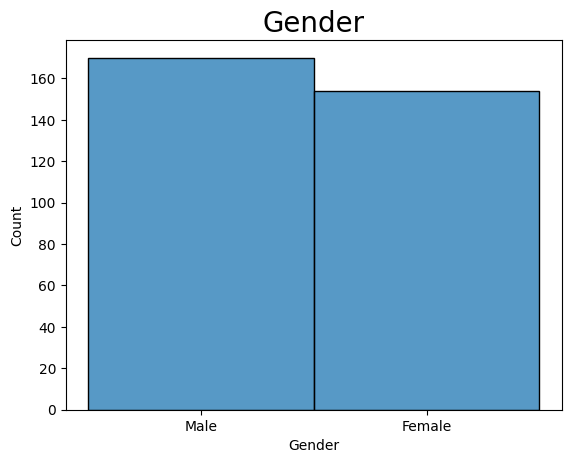

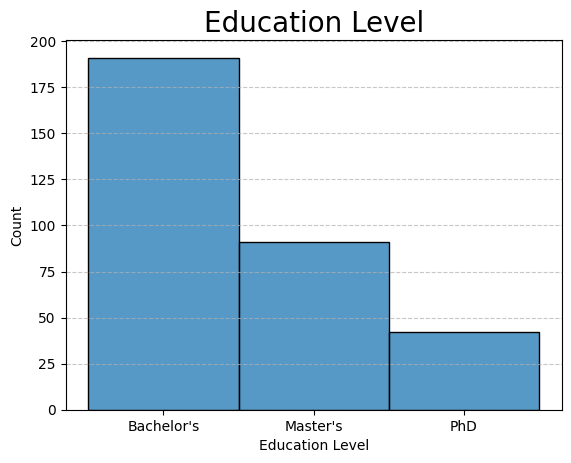

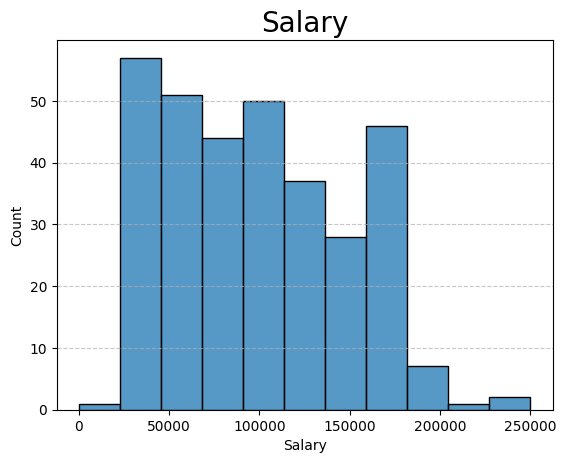

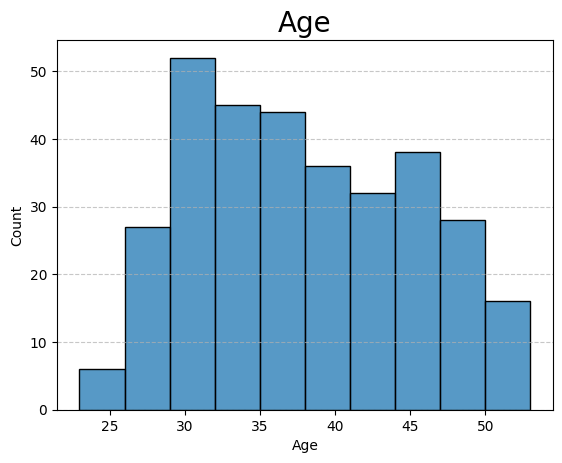

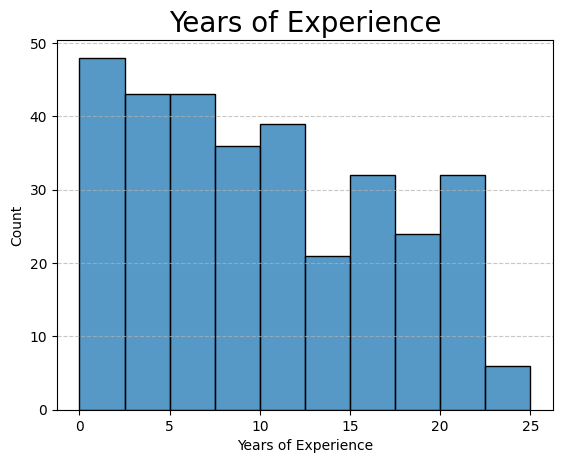

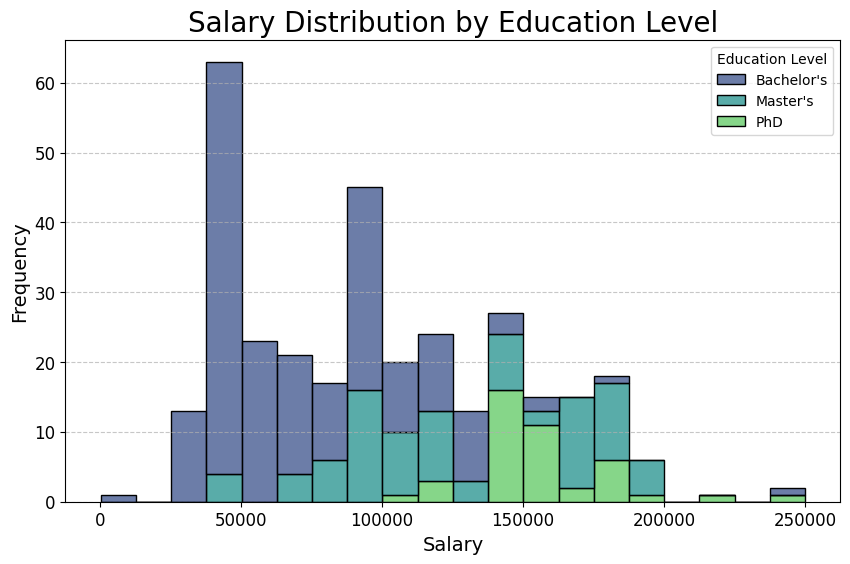

In [48]:
#Ein Histogramm für die folgenden Spalten/Features erstellen um diese zu visualisieren:

#Geschlecht (Gender):
plt.title('Gender', fontsize=20)
sns.histplot(df['Gender'])
plt.show()

#Bildungsgrad (Education Level):
plt.title('Education Level', fontsize=20)
sns.histplot(df['Education Level'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#Gehalt (Salary):
plt.title('Salary', fontsize=20)
plt.grid(axis='y', linestyle='--', alpha=0.7)
sns.histplot(df['Salary'])
plt.show()

#Alter in Jahren (Age):
plt.title('Age', fontsize=20)
plt.grid(axis='y', linestyle='--', alpha=0.7)
sns.histplot(df['Age'])
plt.show()

#Berufserfahrung in Jahren (Years of Experience):
plt.title('Years of Experience', fontsize=20)
plt.grid(axis='y', linestyle='--', alpha=0.7)
sns.histplot(df['Years of Experience'])
plt.show()

#Größe und Darstellung der Diagramme anpassen, um für bessere Visualisierung und Lesbarkeit zu sorgen:
plt.figure(figsize=(10, 6))

#Visualisierung der Gehaltsverteilung (salary) in Abhängigkeit vom Bildungsgrad (Education level):
sns.histplot(data=df, x='Salary', hue='Education Level', kde=False, bins=20, palette='viridis', multiple='stack')

#Anpassung der Darstellungselemente des Plots (plt), um die Lesbarkeit und Verständlichkeit der Visualisierung zu verbessern:
plt.title('Salary Distribution by Education Level', fontsize=20)
plt.xlabel('Salary', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

#Die Visualisierung des obigen Plots (plt) als Diagramm anzeigen:
plt.show()

# 5. Train-Test-Split

<img src ="IMG_1723.jpg" width="800" height="500">

In [49]:
#Die Features des DataFrames in quantitative und kategoriale Gruppen aufteilen:
#Grund: einfacher und gezielter Daten analysieren bzw. visualisieren
quant = ["Age", "Years of Experience"]
cat = ["Gender", "Education Level"]

In [50]:
#Daten in Trainings- und Testdaten unterteilen in einen 80%-20% split:
#Grund: Modelle zu trainieren und anschließend auf neuen Daten zu testen, ohne die gleichen Daten für beide Zwecke zu verwenden.
from sklearn.model_selection import train_test_split
train, test = train_test_split(df, random_state=0, train_size=0.8)
#random_state=0: Sichert reproduzierbare Datenaufteilung.
#train_size=0.8: 80% der Daten für das Training, 20% für das Testen.

# 6. Data Preprocessing

In [51]:
#Berechnete statistische Werte für die quantitativen Features des Trainingsdatensatzes (train) überblicken:
#(Mittelwert, Standardabweichung, Minimum, Maximum und der Quartile sowie Median)
train.describe()

,Age,Years of Experience,Salary
count,259.000000,259.000000,259.000000
mean,37.343629,10.067568,101005.212355
std,7.165923,6.657766,49182.007151
min,23.000000,0.000000,350.000000
25%,31.000000,4.000000,55000.000000
50%,36.000000,9.000000,95000.000000
75%,43.500000,16.000000,140000.000000
max,53.000000,25.000000,250000.000000


In [52]:
#Übersicht über die Häufigkeit und Verteilung der Werte in den kategorialen Features des Trainingsdatensatzes (train):
train[cat].describe()

,Gender,Education Level
count,259,259
unique,2,3
top,Male,Bachelor's
freq,138,155


In [53]:
#Häufigkeiten der verschiedenen Bildungsgrade (Education Level) in Verbindung mit dem Geschlecht (Gender) bzw. dessen Anzahl:
train[cat].value_counts()

Gender  Education Level
Male    Bachelor's         82
Female  Bachelor's         73
Male    Master's           36
Female  Master's           33
Male    PhD                20
Female  PhD                15
Name: count, dtype: int64

In [54]:
#Korrelationsmatrix:
#Berechnen, wie stark die lineare Abhängigkeit der folgenden numerischen Features im Trainingsdatensatz (train) miteinander korrelieren:
#Grund: mögliche Zusammenhänge zu erkennen oder redundante Merkmale zu identifizieren.
train.corr(method='pearson', numeric_only=True)

,Age,Years of Experience,Salary
Age,1.000000,0.978760,0.917238
Years of Experience,0.978760,1.000000,0.927164
Salary,0.917238,0.927164,1.000000


In [55]:
#Die Eingabevariablen und Zielvariablen separat halten, um sie für maschinelles Lernen zu verwenden (Modelltraining und -bewertung):
X_train = train.drop(columns=['Salary'])
y_train = train['Salary']
X_test = test.drop(columns=['Salary'])
y_test = test['Salary']

In [56]:
#Anlegen der Pipeline:
from sklearn.pipeline import Pipeline
#Für die quantitativen Werte wird der StandardScaler verwendet:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
#Für die kategorischen beim Feature "Gender" der OneHotEncoder:
#Für "Education Level" der OrdinalEncoder, da hier eine natürliche Ordnung vorliegt:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

education_order = [[ "Bachelor's", "Master's", 'PhD']]

cat_pipeline = ColumnTransformer(
    transformers=[
        ('gender_ohe', OneHotEncoder(), ['Gender']),
        ('education_ordinal', OrdinalEncoder(categories=education_order), ['Education Level'])
    ],
    remainder='passthrough'
)

quant_pipeline = Pipeline([
        ('std_scaler', StandardScaler()),
    ])


full_pipeline = ColumnTransformer([
  ("quant", quant_pipeline, quant), 
  ("cat", cat_pipeline, cat),
])

In [57]:
#Transformation der Daten mit Pipelines:
#Die Pipelines werden mit fit_transform auf die Trainingsdaten angepasst, wodurch sie die Transformation lernen und durchführen.
#Für die Testdaten wird transform genutzt, um dieselben Parameter wie bei den Trainingsdaten anzuwenden.
#Dadurch entsteht ein einheitlich vorbereiteter Datensatz für das Modelltraining.
X_train = full_pipeline.fit_transform(X_train)
X_test = full_pipeline.transform(X_test)

# 7. Model anlegen und Validieren
### Lineare Regression

In [58]:
#Lineare Regression importieren und bereitmachen:
#Grund: Beziehungen zwischen unabhängigen (Eingabe-) und abhängigen (Ziel-)Variablen zu modellieren.
from sklearn.linear_model import LinearRegression
model_lg = LinearRegression()

In [59]:
#Dimensionen (Anzahl der Zeilen und Spalten) der Trainingsdaten der Features:
X_train.shape
#Dimensionen (Anzahl der Einträge) der Zielvariable im Trainingsdatensatz:
y_train.shape

(259,)

In [60]:
#Der Befehl trainiert das lineare Regressionsmodell model_lg mit den Trainingsdaten:
model_lg.fit(X_train, y_train)

LinearRegression()

In [61]:
#Führt eine Kreuzvalidierung für das lineare Regressionsmodell model_lg durch:
#Grund: die Leistung auf den Trainingsdaten zu bewerten.
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_validate 
cross_validate(model_lg, X_train, y_train, scoring='r2', return_train_score=True)

{'fit_time': array([0.00270939, 0.00237179, 0.0017004 , 0.00146198, 0.00156999]),
 'score_time': array([0.00115228, 0.0010221 , 0.00077057, 0.0006485 , 0.00084114]),
 'test_score': array([0.92830323, 0.91127611, 0.8543474 , 0.91789781, 0.8349647 ]),
 'train_score': array([0.88808151, 0.89260738, 0.90768506, 0.89143996, 0.90695657])}

### KNN mit Hyperparameter K

In [62]:
#Importeren und verwenden des KNN_Modells (K-Nearest Neighbors):
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV

#Beschreibung:
#   - Für das Modell werden die Parameter 1-5 für nächstgelegenen Nachbarn ausprobiert.
#   - Dann wird die Effektivität angezeigt
#   - Beste Parameter = 5, da der mean_test_score (druchschnittliches Testergebnis) hier der höchste ist
#   - Das Modell neigt zum Overfitten (Kann nicht gut mit neuen Daten umgehen. Orientiert sich zu stark am Trainingssatz).


model_knn= KNeighborsRegressor()
parameter = {'n_neighbors': [1,2,3,4,5]}
grid_search = GridSearchCV(model_knn, parameter, scoring='r2', return_train_score=True, cv=3)
grid_search.fit(X_train, y_train)
pd.DataFrame(grid_search.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,mean_train_score,std_train_score
0,0.000951,0.000364,0.001424,0.000840,1,{'n_neighbors': 1},0.870715,0.790798,0.846354,0.835956,0.033444,5,0.955806,0.952814,0.963566,0.957396,0.004531
1,0.000639,0.000043,0.000960,0.000194,2,{'n_neighbors': 2},0.904358,0.801462,0.861468,0.855763,0.042200,1,0.945160,0.961868,0.957158,0.954729,0.007034
2,0.000713,0.000126,0.001018,0.000137,3,{'n_neighbors': 3},0.900351,0.770649,0.842336,0.837779,0.053049,4,0.933441,0.948156,0.942907,0.941501,0.006089
3,0.000849,0.000326,0.000862,0.000035,4,{'n_neighbors': 4},0.901266,0.775538,0.847914,0.841573,0.051524,3,0.923164,0.938609,0.934940,0.932238,0.006589
4,0.000798,0.000284,0.000985,0.000216,5,{'n_neighbors': 5},0.907702,0.787260,0.863889,0.852950,0.049775,2,0.911942,0.935836,0.931264,0.926348,0.010356


# 8. Abschließende Beurteilung der Modelle

In [63]:
#Bewertung der Leistung auf den Tesdaten mit linearer Regression
r2_score(model_lg.predict(X_test), y_test)

0.8767132786221881

In [64]:
#Bewertung der Leistung auf den Testdaten mit K-Nearest-Neighbors (KNN)
model_knn = KNeighborsRegressor(n_neighbors=1)
model_knn.fit(X_train, y_train)
r2_score(model_knn.predict(X_test), y_test)

0.8505321711707766